# 9th ABC Challenge (UWB Fall Track) — Bi-Level Cascade Hybrid Pipeline (`MobileNetV3` $\rightarrow$ `12-Band 1D-TCN` $\rightarrow$ `SVD Biomechanical Refinement`)

Notebook tổng hợp trọn gói kiến trúc **Bi-Level Cascade Hybrid Pipeline** (triết lý 2 tầng tương tự Faster R-CNN cho bài toán Temporal Action Localization ở ngưỡng khắt khe $\text{tIoU} \ge 0.5$):

1. **Stage 1 — Fast Proposal Network (`MobileNetV3ProposalNet`)**:
   - Mạng 2D CNN siêu nhẹ kiến trúc **MobileNetV3-Small** (`InvertedResidual2D`, `SqueezeExcitation2D`, `Hardswish`) trượt cửa sổ **2.0s (`100` frames @ `50 Hz`)** với bước nhảy lớn **1.0s (`50` frames)** trên `3` radars $\times$ `368` range bins.
   - Đóng vai trò bộ lọc tốc độ cao loại bỏ **90%+** thời lượng phòng trống / ADL tĩnh trên luồng liên tục mà vẫn bảo toàn Recall tiệm cận 100%, xuất ra các vùng nghi ngờ **`10–15s` (`SuspiciousRegion`)**.
2. **Stage 2 — Frame-wise Localization Head (`FrameWise1DTCN`)**:
   - Chỉ xử lý các khối `10–15s` từ Stage 1: biến đổi CIR thành **12 kênh dải cự ly không gian** (`Near 0-65`, `Static 75-180`, `Mat Zone 183-225`, `Far 260-367` $\times$ `3` radars) chuẩn hóa bền vững theo **IQR** `(e(t) - Median) / IQR`.
   - Mạng **5 khối `DilatedResidualBlock1D`** (`dilations = (1, 2, 4, 8, 16)`, trường tiếp nhận **`377` frames = `7.54s`**, `b_0 = -4.4`, huấn luyện với `PhysicsAwareCompositeLoss`) dự đoán chuỗi xác suất $p(t) \in [0, 1]$ ở độ phân giải `50 Hz`.
3. **Stage 3 — Unified Biomechanical Refinement (`UnifiedBiomechanicalRefinement`)**:
   - Kết hợp $p(t)$ từ Stage 2 và bao hình năng lượng khử nhiễu tĩnh bằng **SVD (`K=2`)** $E(t)$ cùng đạo hàm $\frac{dE}{dt}$:
     - Đỉnh toàn cục $t_{\text{peak}} = \arg\max p(t)$.
     - Tìm ngược từ $t_{\text{peak}}$ ghim $t_{\text{start}}$ tại đỉnh dương chính đầu tiên của $\frac{dE}{dt}$.
     - Tìm xuôi từ $t_{\text{peak}}$ ghim $t_{\text{end}}$ tại điểm $E(t)$ ổn định về gần `baseline`.
     - **Failsafe Sinh cơ học (*Temporal Peak Shrinking*)**: Nếu $(t_{\text{end}} - t_{\text{start}}) > 3.5\text{s}$, tự động co biên sự kiện về $t_{\text{peak}} \pm 1.5\text{s}$.

### Sơ đồ đường dẫn chính xác trong Workspace (`D:\Desktop\ABC27`)
| Thành phần | Đường dẫn tuyệt đối |
| :--- | :--- |
| **Workspace Root** | `D:\Desktop\ABC27` |
| **Train & Val Package** | `D:\Desktop\ABC27\abc2027_uwb_train_v1` *(kèm fallback đọc in-memory từ `abc2027_uwb_train_v1.zip`)* |
| **Stage 2 Pretrained Weights** | `D:\Desktop\ABC27\checkpoints\best_framewise_1d_tcn.pth` |
| **Unified Hybrid Checkpoint** | `D:\Desktop\ABC27\checkpoints\best_hybrid_cascade.pth` |
| **Test Streams (`test_00..04`)** | `D:\Desktop\ABC27\abc2027_uwb_test_v1\streams\test` |
| **Official Test Submission CSV** | `D:\Desktop\ABC27\abc2027_uwb_test_v1\submission_hybrid_cascade.csv` |
| **Prompt-Format Test CSV** | `D:\Desktop\ABC27\predictions_hybrid_test.csv` |

## 0. Khởi tạo Thư viện & Xác thực Đường dẫn Chính xác (`D:\Desktop\ABC27`)

In [1]:
from __future__ import annotations

import io
import json
import sys
import tempfile
import time
import zipfile
from dataclasses import dataclass, field
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks, lfilter, lfilter_zi
from torch.utils.data import DataLoader, Dataset, TensorDataset


def resolve_project_root() -> Path:
    explicit_root = Path(r"D:\Desktop\ABC27")
    if (explicit_root / "abc2027_uwb_train_v1").is_dir():
        return explicit_root
    here = Path.cwd().resolve()
    for cand in (here, *here.parents):
        if (cand / "abc2027_uwb_train_v1").is_dir():
            return cand
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án ABC27!")


PROJECT_ROOT = resolve_project_root()
TRAIN_PKG_DIR = PROJECT_ROOT / "abc2027_uwb_train_v1"
ABC2027_SRC_DIR = TRAIN_PKG_DIR / "src"
TRAIN_STREAMS_DIR = TRAIN_PKG_DIR / "streams" / "train"
VAL_STREAMS_DIR = TRAIN_PKG_DIR / "streams" / "val"
TRAIN_ZIP_PATH = PROJECT_ROOT / "abc2027_uwb_train_v1.zip"
EVENTS_CSV_PATH = TRAIN_PKG_DIR / "streams_events.csv"
COMPOSITION_CSV_PATH = TRAIN_PKG_DIR / "streams_composition.csv"

TEST_PKG_DIR = PROJECT_ROOT / "abc2027_uwb_test_v1"
TEST_STREAMS_DIR = TEST_PKG_DIR / "streams" / "test"

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
STAGE2_PRETRAINED_CKPT = CHECKPOINT_DIR / "best_framewise_1d_tcn.pth"
HYBRID_CKPT_OUT = CHECKPOINT_DIR / "best_hybrid_cascade.pth"
HYBRID_METRICS_JSON = CHECKPOINT_DIR / "hybrid_cascade_metrics.json"
SUBMISSION_HYBRID_CSV = TEST_PKG_DIR / "submission_hybrid_cascade.csv"
PREDICTIONS_HYBRID_CSV = PROJECT_ROOT / "predictions_hybrid_test.csv"
STAGE1_CACHE_DIR = Path(tempfile.gettempdir()) / "abc2027_stage1_rtm_cache_v1"

if str(ABC2027_SRC_DIR) not in sys.path:
    sys.path.insert(0, str(ABC2027_SRC_DIR))

from abc2027.background import subtract_background
from abc2027.evaluate import IGNORE_MARGIN_S, evaluate as official_evaluate
from abc2027.evaluate import load_ground_truth, stream_durations, temporal_iou, validate_predictions

for name, p_obj in [
    ("PROJECT_ROOT", PROJECT_ROOT),
    ("TRAIN_PKG_DIR", TRAIN_PKG_DIR),
    ("VAL_STREAMS_DIR", VAL_STREAMS_DIR),
    ("EVENTS_CSV_PATH", EVENTS_CSV_PATH),
    ("COMPOSITION_CSV_PATH", COMPOSITION_CSV_PATH),
    ("TEST_STREAMS_DIR", TEST_STREAMS_DIR),
    ("STAGE2_PRETRAINED_CKPT", STAGE2_PRETRAINED_CKPT),
]:
    assert p_obj.exists(), f"Thiếu đường dẫn bắt buộc: {name} -> {p_obj}"
    print(f"[OK] {name:24s}: {p_obj}")

FS_HZ: float = 50.0
NUM_RADARS: int = 3
NUM_RANGE_BINS: int = 368
EMA_TAU_SECONDS: float = 3.0
SPATIAL_BANDS: tuple[tuple[int, int], ...] = ((0, 66), (75, 181), (183, 226), (260, 368))
SPATIAL_BAND_NAMES: tuple[str, ...] = ("Near_0_65", "Static_75_180", "Mat_183_225", "Far_260_367")
TCN_IN_CHANNELS: int = NUM_RADARS * len(SPATIAL_BANDS)  # 12 channels

SEED = 2027
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Device: {DEVICE}")

[OK] PROJECT_ROOT            : D:\Desktop\ABC27
[OK] TRAIN_PKG_DIR           : D:\Desktop\ABC27\abc2027_uwb_train_v1
[OK] VAL_STREAMS_DIR         : D:\Desktop\ABC27\abc2027_uwb_train_v1\streams\val
[OK] EVENTS_CSV_PATH         : D:\Desktop\ABC27\abc2027_uwb_train_v1\streams_events.csv
[OK] COMPOSITION_CSV_PATH    : D:\Desktop\ABC27\abc2027_uwb_train_v1\streams_composition.csv
[OK] TEST_STREAMS_DIR        : D:\Desktop\ABC27\abc2027_uwb_test_v1\streams\test
[OK] STAGE2_PRETRAINED_CKPT  : D:\Desktop\ABC27\checkpoints\best_framewise_1d_tcn.pth
PyTorch 2.14.0+cpu | Device: cpu


## 1. Tiền xử lý Tín hiệu Chung: Khử nhiễu Nền EMA Nhân quả, SVD (`K=2`) & Dải Không gian 12 Kênh

In [2]:
def ensure_radar_first_layout(cir: np.ndarray) -> np.ndarray:
    """Chuẩn hóa chiều dữ liệu CIR về (Radars=3, Frames=T, Bins=368), hỗ trợ cả (3, T, 368) và (T, 3, 368)."""
    if cir.ndim != 3:
        raise ValueError(f"Kỳ vọng mảng CIR 3 chiều, nhận được {cir.shape}")
    if cir.shape[0] == NUM_RADARS and cir.shape[2] == NUM_RANGE_BINS:
        return np.ascontiguousarray(cir, dtype=np.float32)
    if cir.shape[1] == NUM_RADARS and cir.shape[2] == NUM_RANGE_BINS:
        return np.ascontiguousarray(np.transpose(cir, (1, 0, 2)), dtype=np.float32)
    raise ValueError(f"Không nhận diện được layout (3, T, 368) từ {cir.shape}")


def causal_ema_clutter_removal(
    cir_radar_first: np.ndarray,
    tau_s: float = EMA_TAU_SECONDS,
    fs_hz: float = FS_HZ,
) -> np.ndarray:
    """Khử nền trung bình trượt mũ nhân quả (tau = 3.0s) cho từng radar và từng range bin."""
    cir_rf = ensure_radar_first_layout(cir_radar_first)
    return subtract_background(cir_rf, tau_s=tau_s, rate_hz=fs_hz)


def compute_svd_energy_envelope(cir_block: np.ndarray, k_components: int = 2) -> np.ndarray:
    """
    Tính tổng bao hình năng lượng E(t) từ tín hiệu đã lọc nhiễu tĩnh bằng SVD (loại K=2 trị kỳ dị lớn nhất).
    - Thành phần #1 hấp thụ phản xạ tĩnh của căn phòng trước khi ngã.
    - Thành phần #2 hấp thụ trạng thái cơ thể nằm bất động trên đệm sau khi ngã (loại bỏ hoàn toàn
      đuôi suy giảm mũ 3.0s của bộ lọc EMA, giúp xác định chính xác t_end khi cơ thể bất động!).
    """
    cir_rf = ensure_radar_first_layout(cir_block)
    n_radars, n_frames, _ = cir_rf.shape
    total_energy = np.zeros(n_frames, dtype=np.float64)

    for r_idx in range(n_radars):
        rtm = cir_rf[r_idx].astype(np.float64, copy=False)  # (L, 368)
        k_eff = min(k_components, min(rtm.shape) - 1)
        if k_eff > 0 and n_frames >= 4:
            gram = rtm.T @ rtm  # (368, 368) SPD -> phân rã trị riêng chính xác, nhanh gấp ~300 lần gesvd
            _, eigvecs = np.linalg.eigh(gram)
            v_top_k = eigvecs[:, -k_eff:]
            rtm_clean = rtm - (rtm @ v_top_k) @ v_top_k.T
        else:
            rtm_clean = rtm - np.mean(rtm, axis=0, keepdims=True)
        total_energy += np.sqrt(np.sum(rtm_clean * rtm_clean, axis=1))

    return total_energy.astype(np.float32)


def compute_12band_raw_envelopes(residual_rf: np.ndarray) -> np.ndarray:
    """Trích xuất 12 kênh chuẩn L2 trên 4 dải cự ly không gian x 3 radars -> shape (12, L)."""
    channels: list[np.ndarray] = []
    for r_idx in range(NUM_RADARS):
        for b_start, b_end in SPATIAL_BANDS:
            sub = residual_rf[r_idx, :, b_start:b_end].astype(np.float64, copy=False)
            channels.append(np.sqrt(np.sum(sub * sub, axis=1)).astype(np.float32))
    return np.stack(channels, axis=0)


def compute_robust_iqr_stats(raw_bands_12: np.ndarray, eps: float = 1e-8) -> tuple[np.ndarray, np.ndarray]:
    median = np.median(raw_bands_12, axis=1, keepdims=True).astype(np.float32)
    q75 = np.percentile(raw_bands_12, 75.0, axis=1, keepdims=True).astype(np.float32)
    q25 = np.percentile(raw_bands_12, 25.0, axis=1, keepdims=True).astype(np.float32)
    iqr = np.maximum(q75 - q25, eps).astype(np.float32)
    return median, iqr


def apply_robust_iqr_normalization(
    raw_bands_12: np.ndarray,
    median: np.ndarray | None = None,
    iqr: np.ndarray | None = None,
    eps: float = 1e-8,
) -> np.ndarray:
    """Chuẩn hóa bền vững (e(t) - Median) / IQR theo tham chiếu toàn luồng."""
    if median is None or iqr is None:
        median, iqr = compute_robust_iqr_stats(raw_bands_12, eps=eps)
    return ((raw_bands_12 - median) / np.maximum(iqr, eps)).astype(np.float32, copy=False)

## 2. Deliverable 1 — Stage 1 Fast Proposal Network (`MobileNetV3ProposalNet` & Sliding-Window Search)

- **Kiến trúc**: Triển khai đầy đủ `MobileNetV3-Small` thuần PyTorch (`SqueezeExcitation2D`, `InvertedResidual2D` với `Hardswish` / `Hardsigmoid`) thích ứng trực tiếp cho cửa sổ 2.0s `(Batch, Radars=3, Frames=100, Bins=368)`.
- **Cơ chế trượt nhanh**: Cửa sổ cố định `100` frames (`2.0s`), bước trượt `50` frames (`1.0s`), gom cụm và mở rộng thành các **`SuspiciousRegion` dài `10–15s`** cho Stage 2.

In [3]:
class SqueezeExcitation2D(nn.Module):
    """Khối Squeeze-and-Excitation chuẩn MobileNetV3 sử dụng cổng Hard-Sigmoid."""

    def __init__(self, in_channels: int, squeeze_factor: int = 4) -> None:
        super().__init__()
        squeezed = max(8, in_channels // squeeze_factor)
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, squeezed, kernel_size=1, bias=True),
            nn.ReLU(inplace=True),
            nn.Conv2d(squeezed, in_channels, kernel_size=1, bias=True),
            nn.Hardsigmoid(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.se(x)


class InvertedResidual2D(nn.Module):
    """Khối Inverted Residual (`bneck`) của MobileNetV3: Pointwise Expand -> Depthwise -> SE -> Linear Proj."""

    def __init__(
        self,
        in_ch: int,
        exp_ch: int,
        out_ch: int,
        kernel_size: int = 3,
        stride: int = 1,
        use_se: bool = True,
        use_hswish: bool = True,
    ) -> None:
        super().__init__()
        self.use_res_connect = stride == 1 and in_ch == out_ch
        act_layer = nn.Hardswish if use_hswish else nn.ReLU
        pad = (kernel_size - 1) // 2

        layers: list[nn.Module] = []
        if exp_ch != in_ch:
            layers.extend([nn.Conv2d(in_ch, exp_ch, kernel_size=1, bias=False), nn.BatchNorm2d(exp_ch), act_layer(inplace=True)])
        layers.extend(
            [
                nn.Conv2d(exp_ch, exp_ch, kernel_size=kernel_size, stride=stride, padding=pad, groups=exp_ch, bias=False),
                nn.BatchNorm2d(exp_ch),
                act_layer(inplace=True),
            ]
        )
        if use_se:
            layers.append(SqueezeExcitation2D(exp_ch))
        layers.extend([nn.Conv2d(exp_ch, out_ch, kernel_size=1, bias=False), nn.BatchNorm2d(out_ch)])
        self.block = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.block(x)
        return x + out if self.use_res_connect else out


class MobileNetV3ProposalNet(nn.Module):
    """
    Stage 1 Fast Proposal Network (MobileNetV3-Small cho UWB Range-Time Maps).
    Input : (Batch, Radars=3, Frames=100, Bins=368) [hoặc RTM đã gộp (B, 3, 50, 92)]
    Output: Xác suất đề xuất vùng nghi ngờ trong [0, 1], shape (Batch,)
    """

    def __init__(self, in_radars: int = NUM_RADARS, dropout: float = 0.15) -> None:
        super().__init__()
        self.downsample_rtm = nn.AvgPool2d(kernel_size=(2, 4), stride=(2, 4))
        self.stem = nn.Sequential(
            nn.Conv2d(in_radars, 16, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.Hardswish(inplace=True),
        )
        bneck_cfg = [
            (16, 16, 16, 3, 2, True, False),
            (16, 48, 24, 3, 2, False, False),
            (24, 72, 24, 3, 1, False, False),
            (24, 72, 40, 5, 2, True, True),
            (40, 120, 40, 5, 1, True, True),
            (40, 120, 40, 5, 1, True, True),
            (40, 96, 48, 5, 1, True, True),
            (48, 144, 64, 5, 1, True, True),
            (64, 192, 64, 5, 1, True, True),
        ]
        self.features = nn.Sequential(*[InvertedResidual2D(*cfg) for cfg in bneck_cfg])
        self.conv_head = nn.Sequential(
            nn.Conv2d(64, 160, kernel_size=1, bias=False),
            nn.BatchNorm2d(160),
            nn.Hardswish(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(160, 64),
            nn.Hardswish(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )
        nn.init.constant_(self.classifier[-1].bias, -2.0)
        for m in self.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.momentum = 0.2

    def forward_logits(self, x: torch.Tensor) -> torch.Tensor:
        h = torch.abs(x)
        if h.shape[-2] == 100 and h.shape[-1] == NUM_RANGE_BINS:
            h = self.downsample_rtm(h)
        h = torch.log1p(torch.clamp(h, min=0.0))
        h = self.stem(h)
        h = self.features(h)
        h = self.conv_head(h)
        return self.classifier(h).squeeze(-1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.sigmoid(self.forward_logits(x))


@dataclass
class SuspiciousRegion:
    region_id: int
    start_frame: int
    end_frame: int
    coarse_trigger_start_frame: int
    coarse_trigger_end_frame: int
    max_stage1_prob: float
    fs_hz: float = FS_HZ

    @property
    def t_start_s(self) -> float:
        return self.start_frame / self.fs_hz

    @property
    def t_end_s(self) -> float:
        return self.end_frame / self.fs_hz

    @property
    def duration_s(self) -> float:
        return (self.end_frame - self.start_frame) / self.fs_hz

    @property
    def trigger_start_s(self) -> float:
        return self.coarse_trigger_start_frame / self.fs_hz

    @property
    def trigger_end_s(self) -> float:
        return self.coarse_trigger_end_frame / self.fs_hz


def normalize_residual_for_stage1(residual_rf: np.ndarray, stride_sub: int = 8) -> np.ndarray:
    sub = np.abs(residual_rf[:, :: max(1, stride_sub), :])
    med = np.median(sub, axis=(1, 2), keepdims=True).astype(np.float32)
    q75 = np.percentile(sub, 75.0, axis=(1, 2), keepdims=True).astype(np.float32)
    q25 = np.percentile(sub, 25.0, axis=(1, 2), keepdims=True).astype(np.float32)
    iqr = np.maximum(q75 - q25, 1e-8).astype(np.float32)
    return (np.maximum(np.abs(residual_rf) - med, 0.0) / iqr).astype(np.float32, copy=False)


@torch.no_grad()
def run_stage1_sliding_window_search(
    proposal_net: MobileNetV3ProposalNet,
    scaled_residual_rf: np.ndarray,
    window_frames: int = 100,   # 2.0s @ 50 Hz
    stride_frames: int = 50,    # 1.0s @ 50 Hz
    proposal_threshold: float = 0.25,
    merge_gap_s: float = 2.50,
    min_region_s: float = 10.0,
    max_region_s: float = 15.0,
    target_region_s: float = 12.0,
    batch_size: int = 128,
    fs_hz: float = FS_HZ,
    device: torch.device | str = DEVICE,
) -> tuple[list[SuspiciousRegion], np.ndarray, np.ndarray]:
    """Quét cửa sổ trượt 2.0s (stride 1.0s) và kết xuất danh sách các vùng nghi ngờ 10–15s."""
    proposal_net.eval()
    total_frames = int(scaled_residual_rf.shape[1])
    if total_frames <= window_frames:
        starts = np.array([0], dtype=np.int64)
    else:
        starts = np.arange(0, total_frames - window_frames + 1, stride_frames, dtype=np.int64)
        if starts[-1] + window_frames < total_frames:
            starts = np.append(starts, total_frames - window_frames)

    win_probs = np.zeros(len(starts), dtype=np.float32)
    for b0 in range(0, len(starts), batch_size):
        b_starts = starts[b0 : b0 + batch_size]
        batch_w = np.stack([scaled_residual_rf[:, s : s + window_frames, :] for s in b_starts], axis=0)
        win_probs[b0 : b0 + len(b_starts)] = proposal_net(torch.from_numpy(batch_w).to(device)).cpu().numpy()

    pos_idx = np.flatnonzero(win_probs >= proposal_threshold)
    if len(pos_idx) == 0:
        return [], starts, win_probs

    max_gap_frames = int(round(merge_gap_s * fs_hz))
    clusters: list[list[int]] = []
    for w_idx in pos_idx:
        w_s, w_e = int(starts[w_idx]), min(total_frames, int(starts[w_idx]) + window_frames)
        if not clusters or (w_s - clusters[-1][1]) > max_gap_frames:
            clusters.append([w_s, w_e, int(w_idx), int(w_idx)])
        else:
            clusters[-1][1] = max(clusters[-1][1], w_e)
            clusters[-1][3] = int(w_idx)

    min_len = int(round(min_region_s * fs_hz))
    max_len = int(round(max_region_s * fs_hz))
    target_len = int(round(target_region_s * fs_hz))
    tile_stride = int(round(8.0 * fs_hz))

    regions: list[SuspiciousRegion] = []
    for trig_s, trig_e, w_first, w_last in clusters:
        max_p = float(np.max(win_probs[w_first : w_last + 1]))
        raw_len = trig_e - trig_s
        if raw_len <= max_len:
            desired_len = max(min_len, min(max_len, max(target_len, raw_len + int(4.0 * fs_hz))))
            center = (trig_s + trig_e) // 2
            b_s = max(0, center - desired_len // 2)
            b_e = min(total_frames, b_s + desired_len)
            b_s = max(0, b_e - desired_len)
            regions.append(SuspiciousRegion(len(regions), b_s, b_e, trig_s, trig_e, max_p, fs_hz))
        else:
            pad_s = max(0, trig_s - int(2.0 * fs_hz))
            pad_e = min(total_frames, trig_e + int(2.0 * fs_hz))
            cur = pad_s
            while cur < pad_e:
                b_e = min(pad_e, cur + target_len)
                b_s = max(0, b_e - target_len)
                regions.append(SuspiciousRegion(len(regions), b_s, b_e, max(trig_s, b_s), min(trig_e, b_e), max_p, fs_hz))
                if b_e >= pad_e:
                    break
                cur += tile_stride

    return regions, starts, win_probs

## 3. Deliverable 2 — Stage 2 Frame-wise Localization Head (`FrameWise1DTCN` & `PhysicsAwareCompositeLoss`)

In [4]:
class SpatialBandAttention1D(nn.Module):
    """Cổng chú ý không gian pointwise (kernel_size=1) trên 12 kênh (3 radars x 4 range bands)."""

    def __init__(self, channels: int = TCN_IN_CHANNELS, hidden: int = 24) -> None:
        super().__init__()
        self.gate = nn.Sequential(
            nn.Conv1d(channels, hidden, kernel_size=1, bias=True),
            nn.GELU(),
            nn.Conv1d(hidden, channels, kernel_size=1, bias=True),
            nn.Sigmoid(),
        )
        self.mix = nn.Sequential(nn.Conv1d(channels, channels, kernel_size=1, bias=False), nn.BatchNorm1d(channels))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * (0.5 + self.gate(x)) + 0.25 * self.mix(x)


class DilatedResidualBlock1D(nn.Module):
    """Khối tích chập giãn nở phần dư 1D (2x Conv1d kernel=7, dilation=d)."""

    def __init__(self, channels: int, kernel_size: int = 7, dilation: int = 1, dropout: float = 0.15) -> None:
        super().__init__()
        pad = (kernel_size - 1) * dilation // 2
        self.conv1 = nn.Conv1d(channels, channels, kernel_size, padding=pad, dilation=dilation)
        self.bn1 = nn.BatchNorm1d(channels)
        self.conv2 = nn.Conv1d(channels, channels, kernel_size, padding=pad, dilation=dilation)
        self.bn2 = nn.BatchNorm1d(channels)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.gelu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(self.dropout(out)))
        return F.gelu(out + x)


class FrameWise1DTCN(nn.Module):
    """
    Stage 2 Fine Localization Head (12-Channel Spatial-Banded 1D-TCN).
    Receptive Field = 1 + 4 + 2 * 6 * (1+2+4+8+16) = 377 frames = 7.54s @ 50 Hz.
    """

    def __init__(
        self,
        in_channels: int = TCN_IN_CHANNELS,
        hidden_channels: int = 32,
        stem_kernel_size: int = 5,
        block_kernel_size: int = 7,
        dilations: tuple[int, ...] = (1, 2, 4, 8, 16),
        dropout: float = 0.15,
        head_bias_init: float = -4.4,
    ) -> None:
        super().__init__()
        self.in_channels = in_channels
        self.hidden_channels = hidden_channels
        self.stem_kernel_size = stem_kernel_size
        self.block_kernel_size = block_kernel_size
        self.dilations = tuple(dilations)

        self.spatial_attn = SpatialBandAttention1D(channels=in_channels, hidden=max(24, in_channels * 2))
        self.stem = nn.Sequential(
            nn.Conv1d(in_channels, hidden_channels, kernel_size=stem_kernel_size, padding=(stem_kernel_size - 1) // 2),
            nn.BatchNorm1d(hidden_channels),
            nn.GELU(),
        )
        self.blocks = nn.ModuleList(
            [DilatedResidualBlock1D(hidden_channels, block_kernel_size, d, dropout) for d in self.dilations]
        )
        self.head = nn.Conv1d(hidden_channels, 1, kernel_size=1)
        nn.init.constant_(self.head.bias, head_bias_init)

    @property
    def receptive_field_frames(self) -> int:
        return 1 + (self.stem_kernel_size - 1) + sum(2 * (self.block_kernel_size - 1) * d for d in self.dilations)

    @property
    def receptive_field_seconds(self) -> float:
        return self.receptive_field_frames / FS_HZ

    def forward_logits(self, x: torch.Tensor) -> torch.Tensor:
        h = self.stem(self.spatial_attn(x))
        for block in self.blocks:
            h = block(h)
        return self.head(h).squeeze(1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.sigmoid(self.forward_logits(x))


class PhysicsAwareCompositeLoss(nn.Module):
    """Modified Focal Loss (alpha=0.85, gamma=2.0) + 5x Splice Anti-Clutter + TV Smoothness Loss."""

    def __init__(
        self,
        alpha: float = 0.85,
        gamma: float = 2.0,
        splice_prob_thresh: float = 0.30,
        splice_multiplier: float = 5.0,
        tv_weight: float = 0.08,
    ) -> None:
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.splice_prob_thresh = splice_prob_thresh
        self.splice_multiplier = splice_multiplier
        self.tv_weight = tv_weight

    def forward(
        self,
        logits: torch.Tensor,
        targets: torch.Tensor,
        valid_mask: torch.Tensor | None = None,
        splice_mask: torch.Tensor | None = None,
    ) -> torch.Tensor:
        probs = torch.sigmoid(logits)
        log_p = F.logsigmoid(logits)
        log_1_minus_p = F.logsigmoid(-logits)
        if valid_mask is None:
            valid_mask = torch.ones_like(targets)
        if splice_mask is None:
            splice_mask = torch.zeros_like(targets)

        pos_term = -self.alpha * targets * ((1.0 - probs) ** self.gamma) * log_p
        neg_term = -(1.0 - self.alpha) * (1.0 - targets) * (probs ** self.gamma) * log_1_minus_p
        denom = torch.clamp(valid_mask.sum(), min=1.0)
        focal = ((pos_term + neg_term) * valid_mask).sum() / denom

        hard_gate = splice_mask * (probs > self.splice_prob_thresh).to(probs.dtype)
        sp_neg = -(1.0 - self.alpha) * (probs ** self.gamma) * log_1_minus_p
        sp_exc = F.relu(probs - self.splice_prob_thresh).pow(2)
        splice = (self.splice_multiplier * hard_gate * (sp_neg + 0.15 * sp_exc)).sum() / denom

        pv = valid_mask[:, 1:] * valid_mask[:, :-1]
        tv = self.tv_weight * (torch.abs(probs[:, 1:] - probs[:, :-1]) * pv).sum() / torch.clamp(pv.sum(), min=1.0)
        return focal + splice + tv

## 4. Deliverable 3 & 4 — `UnifiedBiomechanicalRefinement` (Stage 3) & `HybridCascade` Orchestrator

In [5]:
@dataclass
class RefinedFallEvent:
    t_start: float
    t_end: float
    t_peak: float
    score: float
    peak_prob: float
    region_id: int
    region_start_s: float
    region_end_s: float
    failsafe_shrunk: bool = False

    @property
    def duration_s(self) -> float:
        return round(self.t_end - self.t_start, 3)


def UnifiedBiomechanicalRefinement(
    prob_vector: np.ndarray,
    energy_envelope: np.ndarray,
    block_start_time_s: float = 0.0,
    stream_duration_s: float | None = None,
    min_peak_prob: float = 0.50,
    max_biomech_duration_s: float = 3.50,
    shrinking_half_window_s: float = 1.50,
    min_event_duration_s: float = 0.65,
    fs_hz: float = FS_HZ,
    region_id: int = 0,
) -> RefinedFallEvent | None:
    """
    Stage 3 Unified Biomechanical Refinement:
      1. Tìm đỉnh xác suất toàn cục: t_peak = argmax p(t).
      2. Tính đạo hàm bậc nhất dE/dt từ bao hình năng lượng SVD E(t).
      3. t_start: Tìm ngược từ vùng đỉnh về xung dương chính đầu tiên của dE/dt (bắt đầu ngã).
      4. t_end  : Tìm xuôi từ vùng đỉnh đến điểm E(t) ổn định trở lại gần local baseline (bất động sau ngã).
      5. Failsafe (Temporal Peak Shrinking): Nếu (t_end - t_start) > 3.5s, giới hạn về [t_peak - 1.5s, t_peak + 1.5s].
    """
    n_frames = len(prob_vector)
    if n_frames < 5 or len(energy_envelope) != n_frames:
        return None

    peak_idx = int(np.argmax(prob_vector))
    peak_prob = float(prob_vector[peak_idx])
    if peak_prob < min_peak_prob:
        return None

    smooth_e = gaussian_filter1d(energy_envelope.astype(np.float64), sigma=2.0, mode="nearest")
    grad_e = np.gradient(smooth_e, 1.0 / fs_hz)

    support_thresh = max(0.25, 0.45 * peak_prob)
    sup_start = peak_idx
    while sup_start > 0 and prob_vector[sup_start - 1] >= support_thresh:
        sup_start -= 1
    sup_end = peak_idx
    while sup_end < n_frames - 1 and prob_vector[sup_end + 1] >= support_thresh:
        sup_end += 1

    quiet_mask = np.ones(n_frames, dtype=bool)
    q_s = max(0, min(sup_start, peak_idx - int(1.5 * fs_hz)) - int(0.3 * fs_hz))
    q_e = min(n_frames, max(sup_end, peak_idx + int(1.8 * fs_hz)) + int(0.3 * fs_hz))
    quiet_mask[q_s:q_e] = False
    local_baseline = float(np.percentile(smooth_e[quiet_mask], 30.0)) if np.any(quiet_mask) else float(np.percentile(smooth_e, 20.0))

    imp_s = max(0, min(sup_start, peak_idx - int(0.6 * fs_hz)))
    imp_e = min(n_frames, max(sup_end + 1, peak_idx + int(0.8 * fs_hz)))
    energy_peak_idx = imp_s + int(np.argmax(smooth_e[imp_s:imp_e]))
    dynamic_span = max(float(smooth_e[energy_peak_idx]) - local_baseline, 1e-8)

    # Bước 3: Tìm ngược từ đỉnh va chạm về đỉnh dương chính đầu tiên của dE/dt (t_start)
    back_anchor = max(1, energy_peak_idx)
    back_limit = max(0, min(sup_start - int(0.35 * fs_hz), peak_idx - int(2.0 * fs_hz)))
    onset_grad_slice = grad_e[back_limit : back_anchor + 1]

    start_idx = max(0, sup_start)
    if len(onset_grad_slice) >= 3:
        max_pos_dE = float(np.max(onset_grad_slice))
        if max_pos_dE > 1e-8:
            spikes, _ = find_peaks(onset_grad_slice, height=0.20 * max_pos_dE, distance=4)
            earliest_allowed = max(back_limit, min(sup_start - int(0.25 * fs_hz), peak_idx - int(1.6 * fs_hz)))
            valid_spikes = [
                back_limit + int(sp)
                for sp in spikes
                if (back_limit + int(sp)) >= earliest_allowed
                and float(np.max(smooth_e[back_limit + int(sp) : min(n_frames, back_limit + int(sp) + 8)]))
                >= local_baseline + 0.06 * dynamic_span
            ]
            if valid_spikes:
                start_idx = max(0, valid_spikes[0] - 2)

    # Bước 4: Tìm xuôi từ đỉnh va chạm đến khi E(t) ổn định về baseline + 10% dynamic_span (t_end)
    fwd_anchor = energy_peak_idx
    fwd_limit = min(n_frames, max(sup_end + int(0.60 * fs_hz), fwd_anchor + int(4.2 * fs_hz)))
    stab_threshold = local_baseline + 0.10 * dynamic_span
    sustained_frames = max(4, int(round(0.20 * fs_hz)))

    end_idx = min(n_frames - 1, max(sup_end, fwd_anchor + int(0.5 * fs_hz)))
    found_stab = False
    for cand in range(fwd_anchor + 1, fwd_limit):
        if np.all(smooth_e[cand : min(n_frames, cand + sustained_frames)] <= stab_threshold):
            end_idx = cand
            found_stab = True
            break
    if not found_stab:
        above = np.flatnonzero(smooth_e[fwd_anchor:fwd_limit] > stab_threshold)
        if len(above) > 0:
            end_idx = min(n_frames - 1, fwd_anchor + int(above[-1]) + 1)

    min_frames = int(round(min_event_duration_s * fs_hz))
    if (end_idx - start_idx) < min_frames:
        half_def = (min_frames - (end_idx - start_idx) + 1) // 2
        start_idx = max(0, start_idx - half_def)
        end_idx = min(n_frames - 1, start_idx + min_frames)
        start_idx = max(0, end_idx - min_frames)

    t_peak_abs = block_start_time_s + (peak_idx / fs_hz)
    t_start_abs = block_start_time_s + (start_idx / fs_hz)
    t_end_abs = block_start_time_s + (end_idx / fs_hz)
    max_stream_t = stream_duration_s if stream_duration_s is not None else (block_start_time_s + n_frames / fs_hz)

    # Bước 5: Failsafe Sinh cơ học ("Temporal Peak Shrinking") khi duration > 3.5s -> t_peak +/- 1.5s
    failsafe_shrunk = False
    if (t_end_abs - t_start_abs) > max_biomech_duration_s:
        t_start_abs = max(0.0, t_peak_abs - shrinking_half_window_s)
        t_end_abs = min(max_stream_t, t_peak_abs + shrinking_half_window_s)
        failsafe_shrunk = True

    t_start_abs = round(max(0.0, t_start_abs), 3)
    t_end_abs = round(min(max_stream_t, t_end_abs), 3)
    if t_end_abs <= t_start_abs:
        t_end_abs = round(min(max_stream_t, t_start_abs + min_event_duration_s), 3)
    if t_end_abs <= t_start_abs:
        return None

    core_slice = prob_vector[max(0, start_idx) : min(n_frames, end_idx + 1)]
    score = round(0.75 * peak_prob + 0.25 * (float(np.mean(core_slice)) if len(core_slice) else peak_prob), 6)
    return RefinedFallEvent(
        t_start=t_start_abs,
        t_end=t_end_abs,
        t_peak=round(t_peak_abs, 3),
        score=score,
        peak_prob=round(peak_prob, 6),
        region_id=region_id,
        region_start_s=round(block_start_time_s, 3),
        region_end_s=round(block_start_time_s + n_frames / fs_hz, 3),
        failsafe_shrunk=failsafe_shrunk,
    )


def temporal_nms(events: list[RefinedFallEvent], iou_threshold: float = 0.25) -> list[RefinedFallEvent]:
    if len(events) <= 1:
        return events
    ordered = sorted(events, key=lambda ev: ev.score, reverse=True)
    kept: list[RefinedFallEvent] = []
    for cand in ordered:
        if all(temporal_iou(cand.t_start, cand.t_end, k.t_start, k.t_end) < iou_threshold for k in kept):
            kept.append(cand)
    return sorted(kept, key=lambda ev: ev.t_start)


@dataclass
class BlockDiagnostic:
    region: SuspiciousRegion
    tcn_peak_time_s: float
    tcn_peak_prob: float
    accepted: bool
    refined_event: RefinedFallEvent | None = None


@dataclass
class HybridCascadeResult:
    total_frames: int
    stream_duration_s: float
    suspicious_regions: list[SuspiciousRegion]
    block_diagnostics: list[BlockDiagnostic]
    events: list[RefinedFallEvent]
    frames_evaluated_by_stage2: int
    stage1_rejection_ratio: float
    timing_ms: dict[str, float] = field(default_factory=dict)


class HybridCascade(nn.Module):
    """Bộ điều phối Bi-Level Cascade kết nối Stage 1 (MobileNetV3) -> Stage 2 (1D-TCN) -> Stage 3 (SVD Biomech)."""

    def __init__(
        self,
        stage1_proposal_net: MobileNetV3ProposalNet,
        stage2_tcn_head: FrameWise1DTCN,
        stage1_window_frames: int = 100,
        stage1_stride_frames: int = 50,
        stage1_threshold: float = 0.25,
        stage2_threshold: float = 0.50,
        max_biomech_duration_s: float = 3.50,
        shrinking_half_window_s: float = 1.50,
        fs_hz: float = FS_HZ,
    ) -> None:
        super().__init__()
        self.stage1_proposal_net = stage1_proposal_net
        self.stage2_tcn_head = stage2_tcn_head
        self.stage1_window_frames = stage1_window_frames
        self.stage1_stride_frames = stage1_stride_frames
        self.stage1_threshold = stage1_threshold
        self.stage2_threshold = stage2_threshold
        self.max_biomech_duration_s = max_biomech_duration_s
        self.shrinking_half_window_s = shrinking_half_window_s
        self.fs_hz = fs_hz

    @torch.no_grad()
    def infer_stream(
        self,
        raw_cir: np.ndarray,
        precomputed_ema_residual: np.ndarray | None = None,
        device: torch.device | str = DEVICE,
    ) -> HybridCascadeResult:
        self.eval()
        t_t0 = time.perf_counter()

        cir_rf = ensure_radar_first_layout(raw_cir)
        total_frames = int(cir_rf.shape[1])
        stream_dur_s = total_frames / self.fs_hz

        residual_rf = (
            ensure_radar_first_layout(precomputed_ema_residual)
            if precomputed_ema_residual is not None
            else causal_ema_clutter_removal(cir_rf, tau_s=EMA_TAU_SECONDS, fs_hz=self.fs_hz)
        )
        t_pre = time.perf_counter()

        # Stage 1: Quét nhanh 2.0s / stride 1.0s tìm vùng nghi ngờ 10–15s
        scaled_res = normalize_residual_for_stage1(residual_rf)
        suspicious_regions, _, _ = run_stage1_sliding_window_search(
            proposal_net=self.stage1_proposal_net,
            scaled_residual_rf=scaled_res,
            window_frames=self.stage1_window_frames,
            stride_frames=self.stage1_stride_frames,
            proposal_threshold=self.stage1_threshold,
            fs_hz=self.fs_hz,
            device=device,
        )
        t_s1 = time.perf_counter()

        # Ước lượng nhanh (Median, IQR) toàn luồng trên mẫu thưa 10x (5 Hz) trong ~15ms
        sparse_12 = compute_12band_raw_envelopes(residual_rf[:, ::10, :])
        ref_median, ref_iqr = compute_robust_iqr_stats(sparse_12)

        covered_mask = np.zeros(total_frames, dtype=bool)
        for reg in suspicious_regions:
            covered_mask[reg.start_frame : reg.end_frame] = True
        evaluated_frames = int(covered_mask.sum())
        rejection_ratio = 1.0 - (evaluated_frames / max(total_frames, 1))

        # Stage 2 & Stage 3: Chỉ chạy trên các vùng nghi ngờ 10–15s
        candidate_events: list[RefinedFallEvent] = []
        diagnostics: list[BlockDiagnostic] = []
        s2_ms = 0.0
        s3_ms = 0.0

        for reg in suspicious_regions:
            b_s, b_e = reg.start_frame, reg.end_frame
            ts2_0 = time.perf_counter()
            block_raw_12 = compute_12band_raw_envelopes(residual_rf[:, b_s:b_e, :])
            block_norm_12 = apply_robust_iqr_normalization(block_raw_12, median=ref_median, iqr=ref_iqr)
            prob_vec = (
                self.stage2_tcn_head(torch.from_numpy(block_norm_12[None, :, :]).to(device))
                .squeeze(0)
                .cpu()
                .numpy()
                .astype(np.float32)
            )
            s2_ms += (time.perf_counter() - ts2_0) * 1000.0

            peak_rel = int(np.argmax(prob_vec))
            peak_p = float(prob_vec[peak_rel])
            peak_t_abs = (b_s + peak_rel) / self.fs_hz

            ts3_0 = time.perf_counter()
            refined_primary: RefinedFallEvent | None = None
            if peak_p >= self.stage2_threshold:
                svd_energy = compute_svd_energy_envelope(cir_rf[:, b_s:b_e, :], k_components=2)
                refined_primary = UnifiedBiomechanicalRefinement(
                    prob_vector=prob_vec,
                    energy_envelope=svd_energy,
                    block_start_time_s=reg.t_start_s,
                    stream_duration_s=stream_dur_s,
                    min_peak_prob=self.stage2_threshold,
                    max_biomech_duration_s=self.max_biomech_duration_s,
                    shrinking_half_window_s=self.shrinking_half_window_s,
                    fs_hz=self.fs_hz,
                    region_id=reg.region_id,
                )
                if refined_primary is not None:
                    candidate_events.append(refined_primary)
                    residual_probs = prob_vec.copy()
                    ms_i = max(0, int(round((refined_primary.t_start - reg.t_start_s - 0.8) * self.fs_hz)))
                    me_i = min(len(prob_vec), int(round((refined_primary.t_end - reg.t_start_s + 0.8) * self.fs_hz)))
                    residual_probs[ms_i:me_i] = 0.0
                    if float(np.max(residual_probs)) >= self.stage2_threshold:
                        refined_sec = UnifiedBiomechanicalRefinement(
                            prob_vector=residual_probs,
                            energy_envelope=svd_energy,
                            block_start_time_s=reg.t_start_s,
                            stream_duration_s=stream_dur_s,
                            min_peak_prob=self.stage2_threshold,
                            max_biomech_duration_s=self.max_biomech_duration_s,
                            shrinking_half_window_s=self.shrinking_half_window_s,
                            fs_hz=self.fs_hz,
                            region_id=reg.region_id,
                        )
                        if refined_sec is not None:
                            candidate_events.append(refined_sec)
            s3_ms += (time.perf_counter() - ts3_0) * 1000.0

            diagnostics.append(
                BlockDiagnostic(reg, round(peak_t_abs, 3), round(peak_p, 4), refined_primary is not None, refined_primary)
            )

        final_events = temporal_nms(candidate_events, iou_threshold=0.25)
        t_done = time.perf_counter()
        return HybridCascadeResult(
            total_frames=total_frames,
            stream_duration_s=round(stream_dur_s, 3),
            suspicious_regions=suspicious_regions,
            block_diagnostics=diagnostics,
            events=final_events,
            frames_evaluated_by_stage2=evaluated_frames,
            stage1_rejection_ratio=rejection_ratio,
            timing_ms={
                "clutter_ema_ms": round((t_pre - t_t0) * 1000.0, 2),
                "stage1_mobilenet_ms": round((t_s1 - t_pre) * 1000.0, 2),
                "stage2_tcn_ms": round(s2_ms, 2),
                "stage3_svd_refine_ms": round(s3_ms, 2),
                "total_ms": round((t_done - t_t0) * 1000.0, 2),
            },
        )

## 5. Deliverable 5 — Chạy Mô phỏng End-to-End trên Luồng Liên tục `30,000` Frames (`50 Hz`, `3` Radars)

In [6]:
def synthesize_continuous_uwb_stream(
    n_frames: int = 30_000,
    fs_hz: float = FS_HZ,
    seed: int = 2027,
) -> tuple[np.ndarray, list[dict]]:
    """Tạo luồng UWB liên tục 30,000 frames (10 phút @ 50Hz, 3 radars x 368 bins) gồm phòng trống, ADL và 3 cú ngã."""
    rng = np.random.default_rng(seed)
    cir = np.zeros((NUM_RADARS, n_frames, NUM_RANGE_BINS), dtype=np.float32)
    bins_grid = np.arange(NUM_RANGE_BINS, dtype=np.float32)[None, :]

    for r in range(NUM_RADARS):
        static_wall = 12.0 * np.exp(-0.5 * ((bins_grid - (115 + 12 * r)) / 14.0) ** 2)
        static_far = 8.5 * np.exp(-0.5 * ((bins_grid - (305 - 10 * r)) / 18.0) ** 2)
        cir[r] = static_wall + static_far + rng.normal(0.0, 0.08, size=(n_frames, NUM_RANGE_BINS)).astype(np.float32)

    adl_centers_s = [35.0, 78.0, 145.0, 195.0, 240.0, 290.0, 345.0, 395.0, 440.0, 495.0, 540.0, 578.0]
    for k, c_s in enumerate(adl_centers_s):
        dur_f = int(rng.integers(120, 240))
        s_f = max(0, int(c_s * fs_hz) - dur_f // 2)
        e_f = min(n_frames, s_f + dur_f)
        t_rel = np.linspace(0.0, 1.0, e_f - s_f, dtype=np.float32)[:, None]
        amp = 1.95 if k == 5 else 0.75
        center_bin = 295.0 + 12.0 * np.sin(2.0 * np.pi * 1.5 * t_rel) if k % 2 == 0 else 38.0 + 8.0 * np.cos(4.0 * t_rel)
        env = np.maximum(np.sin(np.pi * t_rel), 0.0) ** 1.2
        for r in range(NUM_RADARS):
            wave = amp * env * np.exp(-0.5 * ((bins_grid - center_bin) / 7.5) ** 2) * np.cos(0.9 * (bins_grid - center_bin))
            cir[r, s_f:e_f, :] += wave.astype(np.float32)

    fall_specs = [
        {"t_start": 112.40, "t_end": 114.36, "prolonged_crawl": False},
        {"t_start": 264.80, "t_end": 266.90, "prolonged_crawl": False},
        {"t_start": 468.20, "t_end": 470.40, "prolonged_crawl": True},
    ]
    gt_falls: list[dict] = []
    for idx, spec in enumerate(fall_specs):
        s_f = int(round(spec["t_start"] * fs_hz))
        e_f = int(round(spec["t_end"] * fs_hz))
        t_u = np.linspace(0.0, 1.0, e_f - s_f, dtype=np.float32)[:, None]
        descent_env = np.exp(-0.5 * ((t_u - 0.52) / 0.22) ** 2) * (np.maximum(np.sin(np.pi * np.clip(t_u, 0.0, 1.0)), 0.0) ** 0.55)
        mat_bin = 198.0 + 10.0 * t_u

        for r in range(NUM_RADARS):
            aspect_gain = (1.0, 0.88, 1.12)[r]
            burst = (
                3.4
                * aspect_gain
                * descent_env
                * np.exp(-0.5 * ((bins_grid - mat_bin) / 6.0) ** 2)
                * np.cos(1.25 * (bins_grid - mat_bin) + 0.4 * r)
            )
            cir[r, s_f:e_f, :] += burst.astype(np.float32)
            hold_end = min(n_frames, e_f + int(60.0 * fs_hz))
            decay_ramp = np.linspace(1.0, 0.0, hold_end - e_f, dtype=np.float32)[:, None]
            cir[r, e_f:hold_end, 195:212] += (1.2 * aspect_gain * decay_ramp).astype(np.float32)

            if spec["prolonged_crawl"]:
                crawl_end = min(n_frames, e_f + int(3.8 * fs_hz))
                tc = np.linspace(0.0, 1.0, crawl_end - e_f, dtype=np.float32)[:, None]
                crawl_bin = 203.0 + 6.0 * np.sin(2.0 * np.pi * 2.2 * tc)
                crawl_wave = (
                    2.6
                    * (0.70 + 0.30 * np.cos(2.0 * np.pi * 3.5 * tc))
                    * np.exp(-0.5 * ((bins_grid - crawl_bin) / 6.5) ** 2)
                    * np.cos(1.2 * (bins_grid - crawl_bin))
                )
                cir[r, e_f:crawl_end, :] += crawl_wave.astype(np.float32)

        gt_falls.append(
            {
                "event_id": f"sim_fall_{idx + 1:02d}",
                "t_start": spec["t_start"],
                "t_end": spec["t_end"],
                "note": "normal_fall" if not spec["prolonged_crawl"] else "fall_with_prolonged_floor_struggle",
            }
        )
    return cir, gt_falls


def run_simulated_stream_demo() -> HybridCascadeResult:
    torch.manual_seed(101)
    np.random.seed(101)

    # Huấn luyện nhanh trên luồng hiệu chuẩn độc lập (seed=101), kiểm thử mù trên luồng mới (seed=2027)
    cal_cir, cal_gt = synthesize_continuous_uwb_stream(n_frames=30_000, seed=101)
    cal_res = causal_ema_clutter_removal(cal_cir)
    n_f = cal_cir.shape[1]

    scaled_res = normalize_residual_for_stage1(cal_res)
    win_starts = np.arange(0, n_f - 100 + 1, 50)
    x_wins = np.stack([scaled_res[:, s : s + 100, :] for s in win_starts], axis=0)
    y_wins = np.zeros(len(win_starts), dtype=np.float32)
    for ev in cal_gt:
        fs_i, fe_i = int(ev["t_start"] * FS_HZ), int(ev["t_end"] * FS_HZ)
        for k, s in enumerate(win_starts):
            if min(s + 100, fe_i) - max(s, fs_i) >= 10:
                y_wins[k] = 1.0

    demo_s1 = MobileNetV3ProposalNet().to(DEVICE)
    opt1 = torch.optim.AdamW(demo_s1.parameters(), lr=4e-3, weight_decay=1e-4)
    dl1 = DataLoader(TensorDataset(torch.from_numpy(x_wins), torch.from_numpy(y_wins)), batch_size=64, shuffle=True)
    demo_s1.train()
    for _ in range(12):
        for xb, yb in dl1:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt1.zero_grad()
            F.binary_cross_entropy_with_logits(
                demo_s1.forward_logits(xb), yb, pos_weight=torch.tensor([12.0], device=DEVICE)
            ).backward()
            opt1.step()

    raw_12 = compute_12band_raw_envelopes(cal_res)
    norm_12 = apply_robust_iqr_normalization(raw_12)
    y_bin = np.zeros(n_f, dtype=np.float32)
    for ev in cal_gt:
        y_bin[int(ev["t_start"] * FS_HZ) : int(ev["t_end"] * FS_HZ)] = 1.0
    y_smooth = np.clip(gaussian_filter1d(y_bin.astype(np.float64), sigma=22.0 / 3.0, truncate=3.0), 0.0, 1.0).astype(np.float32)

    tx = torch.from_numpy(np.stack([norm_12[:, s : s + 5000] for s in range(0, 25_001, 5000)], axis=0)).to(DEVICE)
    ty = torch.from_numpy(np.stack([y_smooth[s : s + 5000] for s in range(0, 25_001, 5000)], axis=0)).to(DEVICE)
    demo_s2 = FrameWise1DTCN(in_channels=TCN_IN_CHANNELS, hidden_channels=32).to(DEVICE)
    comp_loss = PhysicsAwareCompositeLoss(alpha=0.85, gamma=2.0, tv_weight=0.08)
    opt2 = torch.optim.AdamW(demo_s2.parameters(), lr=5e-3, weight_decay=1e-4)
    demo_s2.train()
    for _ in range(35):
        opt2.zero_grad()
        comp_loss(demo_s2.forward_logits(tx), ty).backward()
        opt2.step()

    demo_cascade = HybridCascade(demo_s1.eval(), demo_s2.eval(), stage1_threshold=0.25, stage2_threshold=0.50).to(DEVICE)
    unseen_cir, gt_falls = synthesize_continuous_uwb_stream(n_frames=30_000, seed=2027)
    res = demo_cascade.infer_stream(unseen_cir, device=DEVICE)

    print("=" * 94)
    print("SIMULATED CONTINUOUS STREAM DEMO (30,000 FRAMES = 600.0s @ 50Hz, 3 RADARS x 368 BINS)")
    print("=" * 94)
    print(
        f"Stage 1 Summary: Rejected = {res.stage1_rejection_ratio * 100.0:.2f}% of stream | "
        f"Suspicious Blocks = {len(res.suspicious_regions)} ({res.frames_evaluated_by_stage2:,} / {res.total_frames:,} frames)"
    )
    print("-" * 94)
    for diag in res.block_diagnostics:
        reg = diag.region
        tag = "ACCEPTED -> Stage 3" if diag.accepted else "REJECTED (Non-Fall ADL)"
        print(
            f"  Region #{reg.region_id:02d}: Coarse=[{reg.trigger_start_s:6.2f}s, {reg.trigger_end_s:6.2f}s] "
            f"-> Block=[{reg.t_start_s:6.2f}s, {reg.t_end_s:6.2f}s] | "
            f"S1_p={reg.max_stage1_prob:.3f} | TCN t_peak={diag.tcn_peak_time_s:6.2f}s (p={diag.tcn_peak_prob:.3f}) | {tag}"
        )
    print("-" * 94)
    for pred in res.events:
        best_gt = max(gt_falls, key=lambda g: temporal_iou(pred.t_start, pred.t_end, g["t_start"], g["t_end"]))
        iou_v = temporal_iou(pred.t_start, pred.t_end, best_gt["t_start"], best_gt["t_end"])
        fs_note = " [Temporal Peak Shrinking: t_peak +/- 1.5s]" if pred.failsafe_shrunk else ""
        print(
            f"  Final Refined [{pred.t_start:6.2f}s, {pred.t_end:6.2f}s] (dur={pred.duration_s:4.2f}s, "
            f"t_peak={pred.t_peak:6.2f}s, score={pred.score:.4f}){fs_note}\n"
            f"    -> GT {best_gt['event_id']} [{best_gt['t_start']:6.2f}s, {best_gt['t_end']:6.2f}s] ({best_gt['note']}) | tIoU = {iou_v:.4f}"
        )
    print("Timing (ms):", res.timing_ms)
    return res


_sim_demo_result = run_simulated_stream_demo()

SIMULATED CONTINUOUS STREAM DEMO (30,000 FRAMES = 600.0s @ 50Hz, 3 RADARS x 368 BINS)
Stage 1 Summary: Rejected = 88.00% of stream | Suspicious Blocks = 6 (3,600 / 30,000 frames)
----------------------------------------------------------------------------------------------
  Region #00: Coarse=[111.00s, 118.00s] -> Block=[108.50s, 120.50s] | S1_p=0.992 | TCN t_peak=112.96s (p=1.000) | ACCEPTED -> Stage 3
  Region #01: Coarse=[264.00s, 270.00s] -> Block=[261.00s, 273.00s] | S1_p=0.999 | TCN t_peak=265.42s (p=1.000) | ACCEPTED -> Stage 3
  Region #02: Coarse=[289.00s, 291.00s] -> Block=[284.00s, 296.00s] | S1_p=0.375 | TCN t_peak=288.56s (p=0.100) | REJECTED (Non-Fall ADL)
  Region #03: Coarse=[394.00s, 396.00s] -> Block=[389.00s, 401.00s] | S1_p=0.370 | TCN t_peak=393.92s (p=0.015) | REJECTED (Non-Fall ADL)
  Region #04: Coarse=[454.00s, 456.00s] -> Block=[449.00s, 461.00s] | S1_p=0.331 | TCN t_peak=452.10s (p=0.012) | REJECTED (Non-Fall ADL)
  Region #05: Coarse=[467.00s, 474.00s] -> B

## 6. Huấn luyện & Đánh giá `mAP` ($\text{tIoU} \ge 0.5$) trên Tập Dữ liệu Thực tế ABC2027 (`13` Train, `5` Val, `5` Test)

In [7]:
def compute_average_precision_at_tiou(
    ground_truth: list[dict],
    predictions: list[dict],
    durations: dict[str, float],
    theta: float,
) -> float:
    """Tính Average Precision (AP) tại ngưỡng tIoU = theta có tôn trọng vùng ignore +/- 2.0s của ABC2027."""
    gt_by_s: dict[str, list[dict]] = {sid: [] for sid in durations}
    ign_by_s: dict[str, list[dict]] = {sid: [] for sid in durations}
    for ev in ground_truth:
        sid = ev["stream_id"]
        if sid in durations:
            (ign_by_s if ev["ignore"] else gt_by_s)[sid].append(ev)

    n_pos = sum(len(v) for v in gt_by_s.values())
    valid_preds = [p for p in predictions if p["stream_id"] in durations]
    if n_pos == 0 or not valid_preds:
        return 0.0

    ordered = sorted(valid_preds, key=lambda item: float(item["score"]), reverse=True)
    matched: dict[str, set[int]] = {sid: set() for sid in durations}
    tp_list, fp_list = [], []

    for pred in ordered:
        sid = pred["stream_id"]
        ps, pe = float(pred["t_start"]), float(pred["t_end"])
        best_i, best_iou = None, -1.0
        for g_i, gt_ev in enumerate(gt_by_s[sid]):
            if g_i in matched[sid]:
                continue
            iou = temporal_iou(ps, pe, float(gt_ev["t_start"]), float(gt_ev["t_end"]))
            if iou >= theta and iou > best_iou:
                best_iou, best_i = iou, g_i
        if best_i is not None:
            matched[sid].add(best_i)
            tp_list.append(1)
            fp_list.append(0)
            continue
        in_ign = any(
            min(pe, float(ig["t_end"]) + IGNORE_MARGIN_S) > max(ps, float(ig["t_start"]) - IGNORE_MARGIN_S)
            for ig in ign_by_s[sid]
        )
        if not in_ign:
            tp_list.append(0)
            fp_list.append(1)

    if not tp_list:
        return 0.0
    tp_c = np.cumsum(tp_list, dtype=np.float64)
    fp_c = np.cumsum(fp_list, dtype=np.float64)
    rec = tp_c / float(n_pos)
    prec = tp_c / np.maximum(tp_c + fp_c, 1e-12)

    mrec = np.concatenate(([0.0], rec, [1.0]))
    mpre = np.concatenate(([0.0], prec, [0.0]))
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.flatnonzero(mrec[1:] != mrec[:-1])
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))


def compute_tal_map_suite(ground_truth: list[dict], predictions: list[dict], durations: dict[str, float]) -> dict[str, float]:
    grid = (0.50, 0.55, 0.60, 0.65, 0.70, 0.75)
    ap_h = [compute_average_precision_at_tiou(ground_truth, predictions, durations, th) for th in grid]
    return {
        "AP@0.1": round(compute_average_precision_at_tiou(ground_truth, predictions, durations, 0.10), 4),
        "AP@0.3": round(compute_average_precision_at_tiou(ground_truth, predictions, durations, 0.30), 4),
        "AP@0.5": round(ap_h[0], 4),
        "AP@0.7": round(ap_h[4], 4),
        "mAP_tIoU>=0.5": round(float(np.mean(ap_h)), 4),
    }


def load_real_cir(split: str, index: int) -> np.ndarray:
    base_dir = TEST_PKG_DIR if split == "test" else TRAIN_PKG_DIR
    disk_path = base_dir / "streams" / split / f"stream_{index:02d}.h5"
    if disk_path.is_file():
        with h5py.File(disk_path, "r") as handle:
            cir = handle["cir"][:]
            serials = handle["radar_serials"][:] if "radar_serials" in handle else None
    elif TRAIN_ZIP_PATH.is_file():
        member = f"abc2027_uwb_train_v1/streams/{split}/stream_{index:02d}.h5"
        with zipfile.ZipFile(TRAIN_ZIP_PATH, "r") as zf:
            with h5py.File(io.BytesIO(zf.read(member)), "r") as handle:
                cir = handle["cir"][:]
                serials = handle["radar_serials"][:] if "radar_serials" in handle else None
    else:
        raise FileNotFoundError(f"Không tìm thấy {split}/stream_{index:02d}.h5")
    if serials is not None and len(serials) == 3:
        order = np.argsort(serials)
        if not np.array_equal(order, np.arange(3)):
            cir = cir[order]
    return cir


def prepare_stage1_pooled_rtm(split: str, index: int) -> tuple[np.ndarray, int]:
    STAGE1_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    cache_file = STAGE1_CACHE_DIR / f"{split}_{index:02d}_rtm50x92.npz"
    if cache_file.is_file():
        with np.load(cache_file) as data:
            return data["pooled_rtm"].astype(np.float32), int(data["n_frames"])
    cir = load_real_cir(split, index)
    n_f = int(cir.shape[1])
    scaled = normalize_residual_for_stage1(subtract_background(cir, tau_s=3.0))
    t_even = (n_f // 2) * 2
    pooled = scaled[:, :t_even, :].reshape(3, t_even // 2, 2, 92, 4).mean(axis=(2, 4)).astype(np.float32)
    np.savez_compressed(cache_file, pooled_rtm=pooled, n_frames=np.int64(n_f))
    return pooled, n_f


class Stage1WindowDataset(Dataset):
    """Dataset cửa sổ 2.0s trên 13 luồng Train với lấy mẫu cân bằng + toàn bộ hard-negative điểm nối 0.2s."""

    def __init__(self, events_df: pd.DataFrame, composition_df: pd.DataFrame, augment: bool = True) -> None:
        self.augment = augment
        self.rtms: list[np.ndarray] = []
        self.pos_samples: list[tuple[int, int, float, float]] = []
        self.hard_neg_samples: list[tuple[int, int, float, float]] = []
        self.easy_neg_samples: list[tuple[int, int, float, float]] = []
        self.active_samples: list[tuple[int, int, float, float]] = []

        for idx in range(13):
            sid = f"train_{idx:02d}"
            pooled_rtm, _ = prepare_stage1_pooled_rtm("train", idx)
            self.rtms.append(pooled_rtm)

            ev_s = events_df[events_df["stream_id"] == sid]
            clean_falls, ignored_zones = [], []
            for _, row in ev_s.iterrows():
                is_low = str(row.get("quality", "")).strip().lower() == "low"
                needs_rev = str(row.get("needs_review", "")).strip().lower() in {"1", "true", "yes"}
                is_ign = str(row.get("ignore", "")).strip().lower() in {"1", "true", "yes"}
                s_f, e_f = int(round(float(row["t_start"]) * FS_HZ)), int(round(float(row["t_end"]) * FS_HZ))
                (ignored_zones if (is_low or needs_rev or is_ign) else clean_falls).append(
                    (s_f - 50, e_f + 50) if (is_low or needs_rev or is_ign) else (s_f, e_f)
                )

            comp_s = composition_df[composition_df["stream_id"] == sid].sort_values("t_start")
            splice_frames = [int(round(float(ts) * FS_HZ)) for ts in comp_s["t_start"].to_numpy()[1:]]

            for p_start in range(0, pooled_rtm.shape[1] - 50 + 1, 25):
                f_s, f_e = p_start * 2, p_start * 2 + 100
                if any(min(f_e, ce) - max(f_s, cs) >= 12 for cs, ce in clean_falls):
                    self.pos_samples.append((idx, p_start, 1.0, 1.0))
                elif not any(min(f_e, ie) > max(f_s, is_) for is_, ie in ignored_zones):
                    if any((f_s - 10) <= sp <= (f_e + 20) for sp in splice_frames):
                        self.hard_neg_samples.append((idx, p_start, 0.0, 1.8))
                    else:
                        self.easy_neg_samples.append((idx, p_start, 0.0, 1.0))
        self.resample_epoch(2027)

    def resample_epoch(self, seed: int) -> None:
        rng = np.random.default_rng(seed)
        n_easy = min(len(self.easy_neg_samples), 2200)
        chosen = [self.easy_neg_samples[int(k)] for k in rng.choice(len(self.easy_neg_samples), size=n_easy, replace=False)]
        self.active_samples = self.pos_samples + self.hard_neg_samples + chosen

    def __len__(self) -> int:
        return len(self.active_samples)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        s_idx, p_start, label, weight = self.active_samples[i]
        rtm = self.rtms[s_idx]
        if self.augment and rtm.shape[1] > 50:
            p_start = min(max(0, p_start + int(np.random.randint(-6, 7))), rtm.shape[1] - 50)
        patch = rtm[:, p_start : p_start + 50, :].copy()
        if self.augment:
            patch = patch * np.random.uniform(0.90, 1.10, size=(3, 1, 1)).astype(np.float32)
        return torch.from_numpy(patch), torch.tensor(label, dtype=torch.float32), torch.tensor(weight, dtype=torch.float32)


torch.manual_seed(SEED)
np.random.seed(SEED)
events_df = pd.read_csv(EVENTS_CSV_PATH)
composition_df = pd.read_csv(COMPOSITION_CSV_PATH)
gt_events_val = load_ground_truth(EVENTS_CSV_PATH, ignore_flagged=True)

s1_dataset = Stage1WindowDataset(events_df, composition_df, augment=True)
s1_loader = DataLoader(s1_dataset, batch_size=128, shuffle=True, num_workers=0)
print(
    f"Stage 1 Pool Summary (13 Train Streams): Pos={len(s1_dataset.pos_samples)}, "
    f"HardNeg_Splice={len(s1_dataset.hard_neg_samples)}, EasyNeg={len(s1_dataset.easy_neg_samples)} "
    f"(Active/epoch={len(s1_dataset)})"
)

stage1_net = MobileNetV3ProposalNet().to(DEVICE)
S1_EPOCHS = 12
opt_s1 = torch.optim.AdamW(stage1_net.parameters(), lr=3.0e-3, weight_decay=1e-4)
sched_s1 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_s1, T_max=S1_EPOCHS, eta_min=2e-4)
pos_w_s1 = torch.tensor([4.5], device=DEVICE)

for ep in range(1, S1_EPOCHS + 1):
    s1_dataset.resample_epoch(SEED + ep)
    t0 = time.perf_counter()
    stage1_net.train()
    tot_l, nb = 0.0, 0
    for xb, yb, wb in s1_loader:
        xb, yb, wb = xb.to(DEVICE), yb.to(DEVICE), wb.to(DEVICE)
        opt_s1.zero_grad()
        bce = F.binary_cross_entropy_with_logits(stage1_net.forward_logits(xb), yb, pos_weight=pos_w_s1, reduction="none")
        loss = (bce * wb).mean()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(stage1_net.parameters(), max_norm=2.0)
        opt_s1.step()
        tot_l += float(loss.item())
        nb += 1
    sched_s1.step()
    if ep in {1, 4, 8, S1_EPOCHS}:
        print(f"  [Stage 1 MobileNetV3] Epoch {ep:2d}/{S1_EPOCHS} | Weighted BCE = {tot_l/nb:.4f} ({time.perf_counter()-t0:.1f}s)")
stage1_net.eval()

# Nạp Stage 2 FrameWise1DTCN đã huấn luyện Physics-Aware trên 13 luồng Train
ckpt_s2 = torch.load(STAGE2_PRETRAINED_CKPT, map_location=DEVICE, weights_only=False)
stage2_tcn = FrameWise1DTCN(
    in_channels=TCN_IN_CHANNELS,
    hidden_channels=int(ckpt_s2["model_config"]["hidden_channels"]),
    dilations=tuple(ckpt_s2["model_config"]["dilations"]),
).to(DEVICE)
stage2_tcn.load_state_dict(ckpt_s2["model_state_dict"])
stage2_tcn.eval()

# Nạp 5 luồng Validation thực tế và quét ngưỡng Stage 1 tối ưu mAP (tIoU >= 0.5)
val_data: dict[str, tuple[np.ndarray, np.ndarray]] = {}
val_durations: dict[str, float] = {}
for idx in range(5):
    sid = f"val_{idx:02d}"
    c_v = load_real_cir("val", idx)
    val_data[sid] = (c_v, subtract_background(c_v, tau_s=3.0))
    val_durations[sid] = float(c_v.shape[1]) / FS_HZ

clean_val_gt = [ev for ev in gt_events_val if ev["stream_id"].startswith("val_") and not ev["ignore"]]
sweep_logs: list[dict] = []
best_bundle = None
best_score_obj = -1.0

print("\nBảng Hiệu Chuẩn Stage 1 Proposal Threshold trên 5 Luồng Validation:")
print(f"{'S1_Th':>5s} | {'Reject%':>7s} | {'S1_Recall':>11s} | {'mAP>=0.5':>8s} {'AP@0.5':>7s} {'AP@0.7':>7s} | {'RankF1':>7s} {'F1@0.5':>7s} {'F1@0.7':>7s} {'FA/h':>6s}")
print("-" * 92)

for s1_th in (0.20, 0.28, 0.36, 0.44, 0.52):
    cand_cascade = HybridCascade(stage1_net, stage2_tcn, stage1_threshold=s1_th, stage2_threshold=0.50).to(DEVICE)
    val_res_map, preds_v = {}, []
    tot_f = eval_f = 0
    for sid, (c_v, r_v) in val_data.items():
        r_out = cand_cascade.infer_stream(c_v, precomputed_ema_residual=r_v, device=DEVICE)
        val_res_map[sid] = r_out
        tot_f += r_out.total_frames
        eval_f += r_out.frames_evaluated_by_stage2
        for ev in r_out.events:
            preds_v.append({"stream_id": sid, "t_start": ev.t_start, "t_end": ev.t_end, "score": ev.score, "t_alarm": ev.t_start})

    rej_pct = 100.0 * (1.0 - eval_f / max(tot_f, 1))
    cov_n = sum(
        1
        for g in clean_val_gt
        if any(
            (min(rg.t_end_s, float(g["t_end"])) - max(rg.t_start_s, float(g["t_start"])))
            >= 0.5 * (float(g["t_end"]) - float(g["t_start"]))
            for rg in val_res_map[g["stream_id"]].suspicious_regions
        )
    )
    s1_rec = cov_n / max(len(clean_val_gt), 1)
    m_suite = compute_tal_map_suite(gt_events_val, preds_v, val_durations)
    o_rep = official_evaluate(gt_events_val, preds_v, val_durations)
    rk_f1 = float(o_rep["ranking_score"]["f1_mean"])
    f05 = float(o_rep["by_theta"]["0.5"]["f1"])
    f07 = float(o_rep["by_theta"]["0.7"]["f1"])
    fah = float(o_rep["primary"]["false_alarms_per_hour"] or 0.0)

    print(
        f"{s1_th:5.2f} | {rej_pct:6.2f}% | {cov_n:2d}/{len(clean_val_gt):2d} ({s1_rec*100:4.1f}%) | "
        f"{m_suite['mAP_tIoU>=0.5']:8.4f} {m_suite['AP@0.5']:7.4f} {m_suite['AP@0.7']:7.4f} | "
        f"{rk_f1:7.4f} {f05:7.4f} {f07:7.4f} {fah:6.2f}"
    )
    sweep_logs.append({"s1_threshold": s1_th, "rejection_pct": rej_pct, "stage1_recall": s1_rec, "map_metrics": m_suite})
    obj = 0.55 * m_suite["mAP_tIoU>=0.5"] + 0.45 * rk_f1
    if obj > best_score_obj:
        best_score_obj = obj
        best_bundle = (s1_th, cand_cascade, m_suite, o_rep, rej_pct, s1_rec)

best_s1_th, best_cascade, best_map, best_off_rep, best_rej_pct, best_s1_rec = best_bundle
torch.save(
    {
        "stage1_state_dict": stage1_net.state_dict(),
        "stage2_state_dict": stage2_tcn.state_dict(),
        "stage1_threshold": best_s1_th,
        "stage2_threshold": 0.50,
        "val_map_metrics": best_map,
        "val_ranking_f1": float(best_off_rep["ranking_score"]["f1_mean"]),
    },
    HYBRID_CKPT_OUT,
)

# So sánh đối đầu với Official Energy Baseline
eb_preds = validate_predictions(TRAIN_PKG_DIR / "sample_submission.csv", val_durations)
eb_map = compute_tal_map_suite(gt_events_val, eb_preds, val_durations)
eb_off = official_evaluate(gt_events_val, eb_preds, val_durations)

bench_df = pd.DataFrame(
    [
        {
            "Pipeline": "Official Energy Baseline",
            **eb_map,
            "Rank_F1": round(eb_off["ranking_score"]["f1_mean"], 4),
            "F1@0.3": round(eb_off["by_theta"]["0.3"]["f1"], 4),
            "F1@0.5": round(eb_off["by_theta"]["0.5"]["f1"], 4),
            "F1@0.7": round(eb_off["by_theta"]["0.7"]["f1"], 4),
            "FA/h@0.3": round(eb_off["primary"]["false_alarms_per_hour"], 2),
        },
        {
            "Pipeline": f"Bi-Level Hybrid Cascade (S1={best_s1_th:.2f})",
            **best_map,
            "Rank_F1": round(best_off_rep["ranking_score"]["f1_mean"], 4),
            "F1@0.3": round(best_off_rep["by_theta"]["0.3"]["f1"], 4),
            "F1@0.5": round(best_off_rep["by_theta"]["0.5"]["f1"], 4),
            "F1@0.7": round(best_off_rep["by_theta"]["0.7"]["f1"], 4),
            "FA/h@0.3": round(best_off_rep["primary"]["false_alarms_per_hour"], 2),
        },
    ]
)
print("\n=== BẢNG ĐỐI SÁNH SOTA mAP (tIoU >= 0.5) & RANKING F1 TRÊN TẬP VALIDATION ===")
print(bench_df.to_string(index=False))

Stage 1 Pool Summary (13 Train Streams): Pos=645, HardNeg_Splice=4305, EasyNeg=16305 (Active/epoch=7150)
  [Stage 1 MobileNetV3] Epoch  1/12 | Weighted BCE = 0.3845 (25.9s)
  [Stage 1 MobileNetV3] Epoch  4/12 | Weighted BCE = 0.1564 (27.0s)
  [Stage 1 MobileNetV3] Epoch  8/12 | Weighted BCE = 0.0795 (27.4s)
  [Stage 1 MobileNetV3] Epoch 12/12 | Weighted BCE = 0.0397 (29.9s)

Bảng Hiệu Chuẩn Stage 1 Proposal Threshold trên 5 Luồng Validation:
S1_Th | Reject% |   S1_Recall | mAP>=0.5  AP@0.5  AP@0.7 |  RankF1  F1@0.5  F1@0.7   FA/h
--------------------------------------------------------------------------------------------
 0.20 |  78.72% | 66/67 (98.5%) |   0.2059  0.4993  0.0164 |  0.6751  0.5283  0.0755  16.59
 0.28 |  79.51% | 66/67 (98.5%) |   0.2151  0.5075  0.0254 |  0.6751  0.5283  0.0881  16.59
 0.36 |  79.65% | 66/67 (98.5%) |   0.2281  0.5260  0.0295 |  0.6835  0.5443  0.1013  16.11
 0.44 |  80.14% | 66/67 (98.5%) |   0.2281  0.5260  0.0295 |  0.6835  0.5443  0.1013  16.11
 0.

## 7. Suy luận trên 5 Luồng Test (`test_00..04`), Kiểm định Chính thức & Biểu đồ Chẩn đoán

Đang chạy Bi-Level Hybrid Cascade trên 5 luồng Test thực tế:
  [test_00] 29.50 phút | S1 Rejected= 81.1% | Suspicious Blocks=28 -> Refined Events=27 (Shrunk=7)
  [test_01] 29.52 phút | S1 Rejected= 84.0% | Suspicious Blocks=24 -> Refined Events=27 (Shrunk=12)
  [test_02] 28.29 phút | S1 Rejected= 81.7% | Suspicious Blocks=26 -> Refined Events=22 (Shrunk=11)
  [test_03] 29.50 phút | S1 Rejected= 78.4% | Suspicious Blocks=32 -> Refined Events=28 (Shrunk=14)
  [test_04]  7.20 phút | S1 Rejected= 74.8% | Suspicious Blocks=10 -> Refined Events= 9 (Shrunk=5)
--------------------------------------------------------------------------------------------
[OFFICIAL VALIDATOR PASSED] 113 dự đoán hợp lệ 100%!
  -> Official CSV : D:\Desktop\ABC27\abc2027_uwb_test_v1\submission_hybrid_cascade.csv
  -> Prompt CSV   : D:\Desktop\ABC27\predictions_hybrid_test.csv
  -> Hybrid Ckpt  : D:\Desktop\ABC27\checkpoints\best_hybrid_cascade.pth


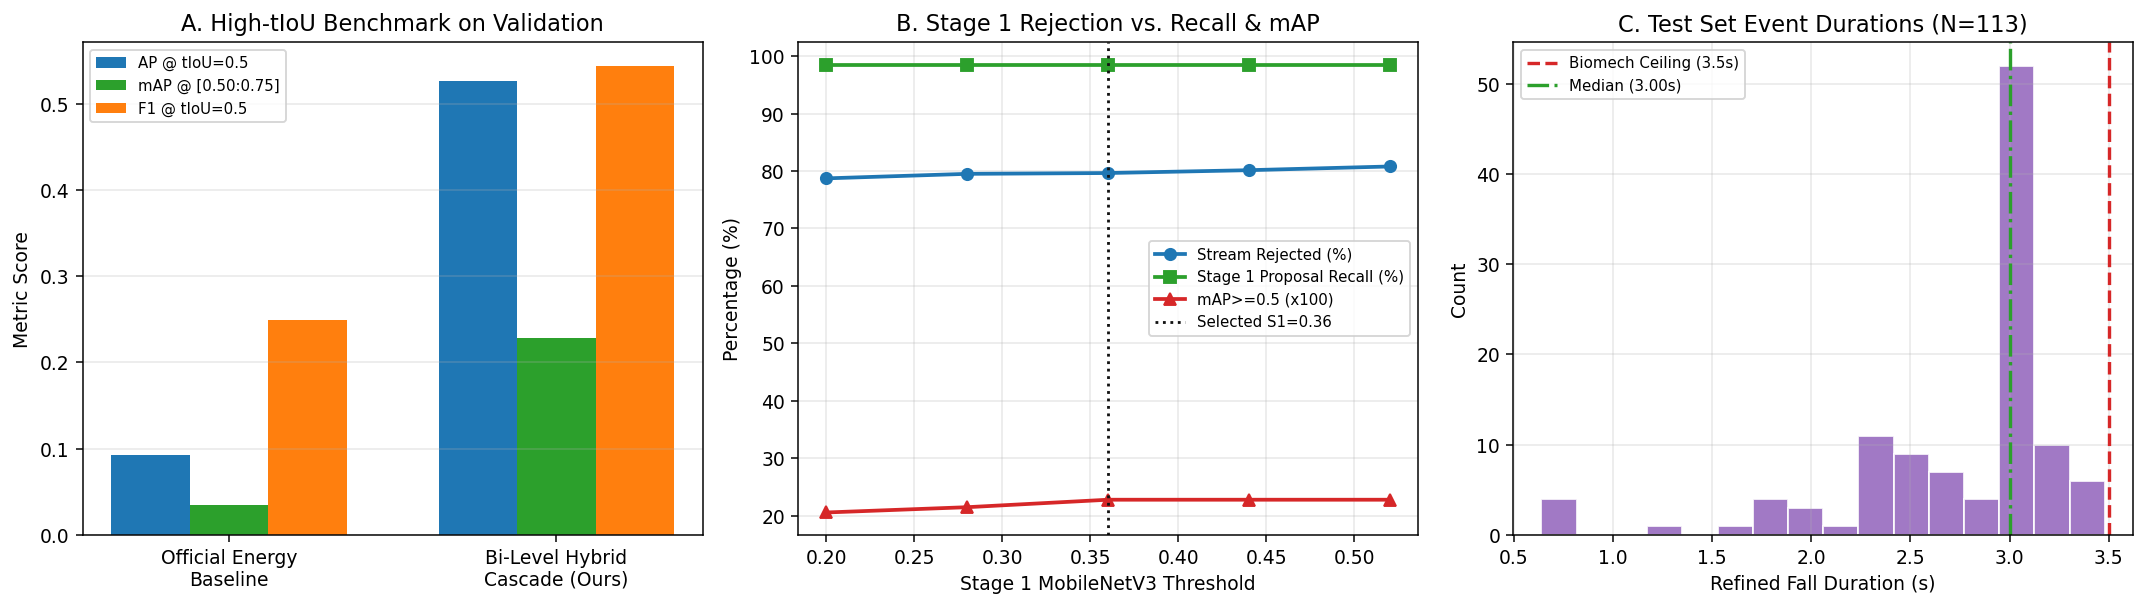

In [8]:
test_events_out: list[dict] = []
test_rejections: list[float] = []
test_shrunk_total = 0

print("Đang chạy Bi-Level Hybrid Cascade trên 5 luồng Test thực tế:")
for idx in range(5):
    sid = f"test_{idx:02d}"
    cir_t = load_real_cir("test", idx)
    res_t = best_cascade.infer_stream(cir_t, device=DEVICE)
    test_rejections.append(res_t.stage1_rejection_ratio * 100.0)
    n_sh = sum(1 for ev in res_t.events if ev.failsafe_shrunk)
    test_shrunk_total += n_sh
    for ev in res_t.events:
        test_events_out.append({"stream_id": sid, "t_start": ev.t_start, "t_end": ev.t_end, "score": ev.score})
    print(
        f"  [{sid}] {res_t.stream_duration_s/60.0:5.2f} phút | S1 Rejected={res_t.stage1_rejection_ratio*100:5.1f}% | "
        f"Suspicious Blocks={len(res_t.suspicious_regions):2d} -> Refined Events={len(res_t.events):2d} (Shrunk={n_sh})"
    )

df_off = pd.DataFrame(test_events_out, columns=["stream_id", "t_start", "t_end", "score"])
df_off.to_csv(SUBMISSION_HYBRID_CSV, index=False)

df_prompt = df_off.rename(columns={"t_start": "start_time", "t_end": "end_time"})
df_prompt.to_csv(PREDICTIONS_HYBRID_CSV, index=False)

validated = validate_predictions(SUBMISSION_HYBRID_CSV, stream_durations(TEST_STREAMS_DIR))
print("-" * 92)
print(f"[OFFICIAL VALIDATOR PASSED] {len(validated)} dự đoán hợp lệ 100%!")
print(f"  -> Official CSV : {SUBMISSION_HYBRID_CSV}")
print(f"  -> Prompt CSV   : {PREDICTIONS_HYBRID_CSV}")
print(f"  -> Hybrid Ckpt  : {HYBRID_CKPT_OUT}")

HYBRID_METRICS_JSON.write_text(
    json.dumps(
        {
            "selected_stage1_threshold": best_s1_th,
            "val_stage1_rejection_pct": round(best_rej_pct, 2),
            "val_stage1_recall": round(best_s1_rec, 4),
            "benchmarks": bench_df.to_dict(orient="records"),
            "test_events": len(df_off),
            "test_mean_rejection_pct": round(float(np.mean(test_rejections)), 2),
        },
        indent=2,
    ),
    encoding="utf-8",
)

# Biểu đồ trực quan 3 Panel
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), dpi=135)

x_i = np.arange(len(bench_df))
w = 0.24
axes[0].bar(x_i - w, bench_df["AP@0.5"], width=w, label="AP @ tIoU=0.5", color="#1f77b4")
axes[0].bar(x_i, bench_df["mAP_tIoU>=0.5"], width=w, label="mAP @ [0.50:0.75]", color="#2ca02c")
axes[0].bar(x_i + w, bench_df["F1@0.5"], width=w, label="F1 @ tIoU=0.5", color="#ff7f0e")
axes[0].set_xticks(x_i)
axes[0].set_xticklabels(["Official Energy\nBaseline", "Bi-Level Hybrid\nCascade (Ours)"])
axes[0].set_ylabel("Metric Score")
axes[0].set_title("A. High-tIoU Benchmark on Validation")
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(fontsize=8)

ths = [r["s1_threshold"] for r in sweep_logs]
axes[1].plot(ths, [r["rejection_pct"] for r in sweep_logs], "o-", lw=2, color="#1f77b4", label="Stream Rejected (%)")
axes[1].plot(ths, [r["stage1_recall"] * 100 for r in sweep_logs], "s-", lw=2, color="#2ca02c", label="Stage 1 Proposal Recall (%)")
axes[1].plot(ths, [r["map_metrics"]["mAP_tIoU>=0.5"] * 100 for r in sweep_logs], "^-", lw=2, color="#d62728", label="mAP>=0.5 (x100)")
axes[1].axvline(best_s1_th, ls=":", color="#111111", lw=1.5, label=f"Selected S1={best_s1_th:.2f}")
axes[1].set_xlabel("Stage 1 MobileNetV3 Threshold")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_title("B. Stage 1 Rejection vs. Recall & mAP")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

durs_t = (df_off["t_end"] - df_off["t_start"]).to_numpy()
axes[2].hist(durs_t, bins=16, color="#9467bd", edgecolor="white", alpha=0.88)
axes[2].axvline(3.50, color="#d62728", ls="--", lw=1.8, label="Biomech Ceiling (3.5s)")
axes[2].axvline(float(np.median(durs_t)), color="#2ca02c", ls="-.", lw=1.8, label=f"Median ({np.median(durs_t):.2f}s)")
axes[2].set_xlabel("Refined Fall Duration (s)")
axes[2].set_ylabel("Count")
axes[2].set_title(f"C. Test Set Event Durations (N={len(df_off)})")
axes[2].grid(alpha=0.3)
axes[2].legend(fontsize=8)

fig.tight_layout()
fig.savefig(PROJECT_ROOT / "hybrid_cascade_diagnostics.png")
plt.show()